(benchmark-fit-time-and-memory-as-the-data-grow)=
# Benchmark: fit time and memory by row count

How long one fit takes, and how much memory it needs, as the training set grows from 1,000 to 90,000 rows. The data are the CPS 1988 wage records {cite:p}`bierens2001integrated`; the model is the same log-wage regression in every library. Above the 22,524 rows of the training split the rows are resampled with replacement, which keeps the covariate distribution and only changes n.

The amount of work is held fixed: mboostrs runs a fixed number of boosting steps, the trees a fixed 400 rounds, pyGAM a fixed smoothing parameter. That isolates how cost grows with n. It is not a statement about how long a tuned analysis takes; the `tune_mstop` row shows that separately.

This page reads a recorded artifact and refits nothing.

:::{note} Recorded before the response-units change
The mboostrs GaussianLSS timings on this page are recorded results. They were recorded with mboostrs 0.2.3 or earlier, when distributional (LSS) and `Quantile` fits boosted the response in the units it was given. Since then these fits divide the response by its standard deviation, boost the rescaled response and map the fitted model back (`response_scale="auto"`), so a step has the same size in any units; `Quantile` also starts at the `tau`-quantile of the response, and takes steps of 0.3 when no control is given. Refitting on the current version gives different numbers. `response_scale=None` with the settings the page states reproduces the recorded fits; [Response units](../implementation/parity_and_bugs.ipynb#response-units) describes the change and its measured effect.
:::

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how fit time and peak memory grow with the number of training rows, at a fixed amount of work |
| **Observed response** | log hourly wage in the CPS 1988 sample |
| **Estimand** | median wall-clock seconds of fit plus prediction, and peak resident-memory growth, per method and training size |
| **Units** | seconds; megabytes |
| **Sampling unit** | one fit in a fresh process |
| **Dependence** | repeats at one size share data and machine; sizes above 22,524 resample rows with replacement |
| **Split / resampling unit** | the first n rows of one shuffled training split (seed 0), resampled above its size |
| **Tuning** | none: mboostrs 1000 steps (500 per parameter for GaussianLSS), trees 400 rounds, pyGAM λ = 0.6; tune_mstop is timed as its own row |
| **Uncertainty** | three repeats up to 10,000 rows and one above; medians reported, no interval |
| **Claim type** | descriptive timing on one machine, single-threaded; ratios between sizes are more transferable across machines than absolute seconds |
:::

In [1]:
from IPython.display import display
import altair as alt
import numpy as np
import polars as pl

from public_tasks import (
    failures, lines, load, memory, paired, protocol, summary, table, warnings_by_method,
)

import json
from pathlib import Path

bench = json.loads(Path("bench_public_scaling.json").read_text())
runs = pl.DataFrame(bench["results"])
display(table(
    protocol(bench), stub="item", stubhead="Item",
    title="What was run", subtitle="One shuffled CPS 1988 training split, grown by resampling",
    notes=["Source: bench_public_scaling.json, written by benches/bench_public_tasks.py."],
))

GT(_tbl_data=shape: (11, 2)
┌───────────────────────┬─────────────────────────────────┐
│ item                  ┆ value                           │
│ ---                   ┆ ---                             │
│ str                   ┆ str                             │
╞═══════════════════════╪═════════════════════════════════╡
│ source                ┆ https://raw.githubusercontent.… │
│ source sha256         ┆ ef5ee9cbf3674f9c…               │
│ train fraction        ┆ 0.8                             │
│ seeds (random splits) ┆ 1                               │
│ trees (fixed setting) ┆ 400 rounds, learning rate 0.05  │
│ …                     ┆ …                               │
│ versions              ┆ mboostrs 0.1.3, polars 2.0.0, … │
│ commit                ┆ 836c450c8c + uncommitted runne… │
│ runner sha256         ┆ ccd6242f4a5b001a…               │
│ measured at (UTC)     ┆ 2026-10-08T22:32:48+00:00       │
│ machine               ┆ Intel(R) Xeon(R) Processor, 8 … │
└───────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10dbb3260>, _boxhead=Boxhead([ColInfo(var='item', type=<ColInfoTypeEnum.stub: 2>, column_label='item', column_align='left', column_width=None), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='value', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f60b200>, _spanners=Spanners([]), _heading=Heading(title='What was run', subtitle='One shuffled CPS 1988 training split, grown by resampling', preheader=None), _stubhead='Item', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dc0d490>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ef77dd0>, _source_notes=['Source: bench_public_scaling.json, written by benches/bench_public_tasks.py.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10eb91e20>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10f5726f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_b

## Time

In [2]:
ORDER = ['statsmodels OLS Mincer', 'mboostrs gamboost (mstop 1000)', 'XGBoost', 'LightGBM', 'pyGAM LinearGAM (fixed lambda)', 'mboostrs gamboost bins=64 (mstop 1000)', 'sklearn HGB', 'CatBoost', 'mboostrs GaussianLSS (mstop 500)', 'mboostrs tune_mstop (tunes and fits)']
medians = (runs.filter(pl.col("status") == "success")
           .group_by("method", "n_train")
           .agg(pl.col("seconds").median(), pl.col("peak_rss_growth_mb").median()))
sizes = sorted(medians["n_train"].unique().to_list())
wide = (medians.pivot(on="n_train", index="method", values="seconds")
        .select("method", *[str(n) for n in sizes])
        .with_columns(pl.col("method").replace_strict({m: i for i, m in enumerate(ORDER)}, default=99).alias("o"))
        .sort("o").drop("o"))
display(table(
    wide, stub="method", stubhead="Method",
    title="Median seconds per fit by training size",
    subtitle="Fit plus prediction, one thread, fixed amount of work",
    labels={str(n): f"{n:,}" for n in sizes},
    better={str(n): "min" for n in sizes}, decimals=3,
    notes=["tune_mstop is not run above 22,524 rows. Bold: the fastest at each size."],
))

GT(_tbl_data=shape: (10, 6)
┌─────────────────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ method                          ┆ 1000     ┆ 3000     ┆ 10000    ┆ 22524    ┆ 90000    │
│ ---                             ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str                             ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═════════════════════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ statsmodels OLS Mincer          ┆ 0.003414 ┆ 0.002825 ┆ 0.006747 ┆ 0.014501 ┆ 0.061809 │
│ mboostrs gamboost (mstop 1000)  ┆ 0.02611  ┆ 0.035801 ┆ 0.06983  ┆ 0.126771 ┆ 0.411738 │
│ XGBoost                         ┆ 0.073812 ┆ 0.098976 ┆ 0.174275 ┆ 0.280927 ┆ 0.927044 │
│ LightGBM                        ┆ 0.157745 ┆ 0.160163 ┆ 0.248165 ┆ 0.384278 ┆ 1.068294 │
│ pyGAM LinearGAM (fixed lambda)  ┆ 0.036595 ┆ 0.053948 ┆ 0.117066 ┆ 0.340355 ┆ 1.306059 │
│ mboostrs gamboost bins=64 (mst… ┆ 0.033144 ┆ 0.05936  ┆ 0.145607 ┆ 0.322646 ┆ 1.626956 │
│ sklearn HGB                     ┆ 0.532587 ┆ 0.525361 ┆ 0.633688 ┆ 0.855097 ┆ 1.816383 │
│ CatBoost                        ┆ 0.10739  ┆ 0.16451  ┆ 0.389263 ┆ 0.717243 ┆ 2.608828 │
│ mboostrs GaussianLSS (mstop 50… ┆ 0.056828 ┆ 0.150825 ┆ 0.497143 ┆ 1.064077 ┆ 7.767626 │
│ mboostrs tune_mstop (tunes and… ┆ 0.076926 ┆ 0.310431 ┆ 5.461929 ┆ 6.615855 ┆ null     │
└─────────────────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10f537aa0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='1000', type=<ColInfoTypeEnum.default: 1>, column_label='1,000', column_align='right', column_width=None), ColInfo(var='3000', type=<ColInfoTypeEnum.default: 1>, column_label='3,000', column_align='right', column_width=None), ColInfo(var='10000', type=<ColInfoTypeEnum.default: 1>, column_label='10,000', column_align='right', column_width=None), ColInfo(var='22524', type=<ColInfoTypeEnum.default: 1>, column_label='22,524', column_align='right', column_width=None), ColInfo(var='90000', type=<ColInfoTypeEnum.default: 1>, column_label='90,000', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f60b6e0>, _spanners=Spanners([]), _heading=Heading(title='Median seconds per fit by training size', subtitle='Fit plus prediction, one thread, fixed amount of work', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f64a000>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f649f40>, _source_notes=['tune_mstop is not run above 22,524 rows. Bold: the fastest at each size.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='1000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='1000', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='1000', rownum=8, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='1000', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='3000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F649A00>, mask=None), grpname=None, colname='3000'

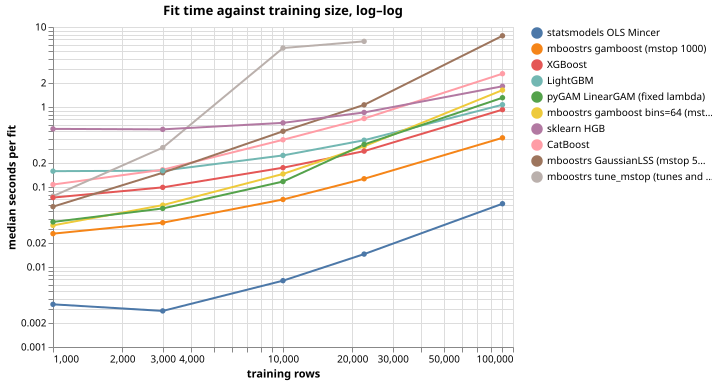

In [3]:
alt.Chart(medians.filter(pl.col("seconds") > 0)).mark_line(point=True).encode(
    x=alt.X("n_train:Q", scale=alt.Scale(type="log"), title="training rows"),
    y=alt.Y("seconds:Q", scale=alt.Scale(type="log"), title="median seconds per fit"),
    color=alt.Color("method:N", sort=ORDER, title=None),
).properties(width=460, height=320, title="Fit time against training size, log–log")

(reading-the-times)=
## Timing comparisons

**The Gaussian mboostrs fit is the fastest boosting fit at every size.** 0.07 s at 10,000 rows and 0.41 s at 90,000, against 1.07 s for LightGBM at the largest size. A Gaussian `gamboost` with these learners runs on the Gram route (the `gaussian_gram` code path, which solves each step from precomputed cross-products of the design matrices): one pass forms each learner's cross-products, and every boosting step after that works on matrices whose size is set by the basis, not by n. Its time still grows 5.9× for nine times the rows, because preparing the data, forming the cross-products and predicting all touch every row; what the route removes is a pass over the rows at each of the 1000 steps.

**Binning each predictor into 64 bins (`bins=64`) makes the fit slower here, not faster.** 1.63 s at 90,000 rows.
Binning exists to avoid storing a dense row-by-basis design for every learner, and it speeds up fits that are on the general
route anyway. The unbinned Gaussian fit here was already on the faster Gram
route, and binning takes it off that route (the fit's execution report, the record of which code path ran, names the fallback
`unsupported_learner_for_gram`), so each of the 1000 steps works through the
rows again.

**GaussianLSS time grows faster than the row count here.** GaussianLSS at 500 steps per
parameter goes from 0.50 s to 7.77 s
(16×). A distributional fit has no Gram shortcut: every step
recomputes each row's gradient for the parameter being updated, so each step
costs a pass over the rows. That alone would make the cost linear in n;
16× for nine times the rows is worse than linear, which is an open item.

**The trees grow more slowly than n from 10,000 rows on.** LightGBM 1.07 s, XGBoost 0.93 s, CatBoost 2.61 s at 90,000 rows: 4.3×, 5.3× and 6.7× for nine times the rows. Each round costs a pass over the rows, but part of every fit is a fixed cost: LightGBM already takes 0.16 s at 1,000 rows. pyGAM, with a fixed λ, solves one penalised least-squares problem: 1.31 s.

**Tuning dominates the mboostrs wall-clock.** `tune_mstop` took 5.5 s at 10,000 rows and 6.6 s at 22,524; it fits five folds along a path that doubles until the cross-validated risk turns, and it returns the full-data fit at the chosen step, so no refit is needed afterwards.

## Memory

In [4]:
wide_mem = (medians.pivot(on="n_train", index="method", values="peak_rss_growth_mb")
            .select("method", *[str(n) for n in sizes])
            .with_columns(pl.col("method").replace_strict({m: i for i, m in enumerate(ORDER)}, default=99).alias("o"))
            .sort("o").drop("o"))
display(table(
    wide_mem, stub="method", stubhead="Method",
    title="Peak resident-memory growth per fit by training size",
    subtitle="VmHWM after the fit minus VmRSS before it, in MB, fresh process per fit",
    labels={str(n): f"{n:,}" for n in sizes},
    better={str(n): "min" for n in sizes}, decimals=1,
    notes=["The high-water mark is reset after imports and data loading. A small fit can "
           "stay inside memory the allocator already holds, which reads as zero growth."],
))

GT(_tbl_data=shape: (10, 6)
┌─────────────────────────────────┬───────────┬───────────┬───────────┬───────────┬────────────┐
│ method                          ┆ 1000      ┆ 3000      ┆ 10000     ┆ 22524     ┆ 90000      │
│ ---                             ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---        │
│ str                             ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64        │
╞═════════════════════════════════╪═══════════╪═══════════╪═══════════╪═══════════╪════════════╡
│ statsmodels OLS Mincer          ┆ 2.808594  ┆ 3.4140625 ┆ 5.964844  ┆ 11.601562 ┆ 38.984375  │
│ mboostrs gamboost (mstop 1000)  ┆ 6.984375  ┆ 8.691406  ┆ 14.050781 ┆ 25.578125 ┆ 83.75      │
│ XGBoost                         ┆ 9.582031  ┆ 10.097656 ┆ 11.183594 ┆ 14.117188 ┆ 28.667969  │
│ LightGBM                        ┆ 7.65625   ┆ 7.984375  ┆ 8.996094  ┆ 11.230469 ┆ 26.742188  │
│ pyGAM LinearGAM (fixed lambda)  ┆ 11.449219 ┆ 14.703125 ┆ 37.820312 ┆ 83.167969 ┆ 331.285156 │
│ mboostrs gamboost bins=64 (mst… ┆ 6.066406  ┆ 6.730469  ┆ 8.7421875 ┆ 12.746094 ┆ 37.070312  │
│ sklearn HGB                     ┆ 3.582031  ┆ 4.363281  ┆ 5.128906  ┆ 7.9921875 ┆ 21.441406  │
│ CatBoost                        ┆ 11.285156 ┆ 11.949219 ┆ 14.074219 ┆ 17.820312 ┆ 37.15625   │
│ mboostrs GaussianLSS (mstop 50… ┆ 7.4296875 ┆ 10.460938 ┆ 26.882812 ┆ 56.140625 ┆ 212.894531 │
│ mboostrs tune_mstop (tunes and… ┆ 11.121094 ┆ 21.464844 ┆ 58.429688 ┆ 115.28125 ┆ null       │
└─────────────────────────────────┴───────────┴───────────┴───────────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10f60b4d0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='1000', type=<ColInfoTypeEnum.default: 1>, column_label='1,000', column_align='right', column_width=None), ColInfo(var='3000', type=<ColInfoTypeEnum.default: 1>, column_label='3,000', column_align='right', column_width=None), ColInfo(var='10000', type=<ColInfoTypeEnum.default: 1>, column_label='10,000', column_align='right', column_width=None), ColInfo(var='22524', type=<ColInfoTypeEnum.default: 1>, column_label='22,524', column_align='right', column_width=None), ColInfo(var='90000', type=<ColInfoTypeEnum.default: 1>, column_label='90,000', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f6dc140>, _spanners=Spanners([]), _heading=Heading(title='Peak resident-memory growth per fit by training size', subtitle='VmHWM after the fit minus VmRSS before it, in MB, fresh process per fit', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10de163c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f6dcd70>, _source_notes=['The high-water mark is reset after imports and data loading. A small fit can stay inside memory the allocator already holds, which reads as zero growth.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F6DCE90>, mask=None), grpname=None, colname='1000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F6DCE90>, mask=None), grpname=None, colname='1000', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F6DCE90>, mask=None), grpname=None, colname='1000', rownum=8, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F6DCE90>, mask=None), grpname=None, colname='1000', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F6DCE90>, mask=None), grpname=None, colname='3000', ro

At 90,000 rows the Gaussian `gamboost` grows by 84 MB and the
GaussianLSS fit by 213 MB, against 27 MB for
LightGBM and 331 MB for pyGAM. The LSS figure
roughly quadruples from 22,524 rows (56 MB) to 90,000, in step with n;
The cause identified is learner data stored densely per row. With `bins=64` the Gaussian fit
grows by 37 MB instead of 84: smaller learner storage is what
binning is for, and here it costs fit time, 1.63 s against 0.41 s at 90,000 rows.

## Reproduction

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1 \
  python benches/bench_public_tasks.py --task scaling \
  --out docs/book/benchmarks/bench_public_scaling.json
```

The results file `bench_public_scaling.json` records the source URL and sha256, the seeds, the tree settings, the thread environment, library versions, the runner's sha256, the commit and the machine.